DATASET OVERVIEW
Dataset shape: (7043, 21)

First five rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

 

C:\Users\kgaogelo Tladi\AppData\Local\Temp\ipykernel_38492\980683394.py:164: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


Logistic Regression trained successfully.
Random Forest trained successfully.

LOGISTIC REGRESSION

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


RANDOM FOREST

Classification report:
              precision    recall  f1-score   support

    No Churn       0.86      0.81      0.84      1035
       Churn       0.56      0.65      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409


MODEL COMPARISON
                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                              
Logistic Regression     0.738 

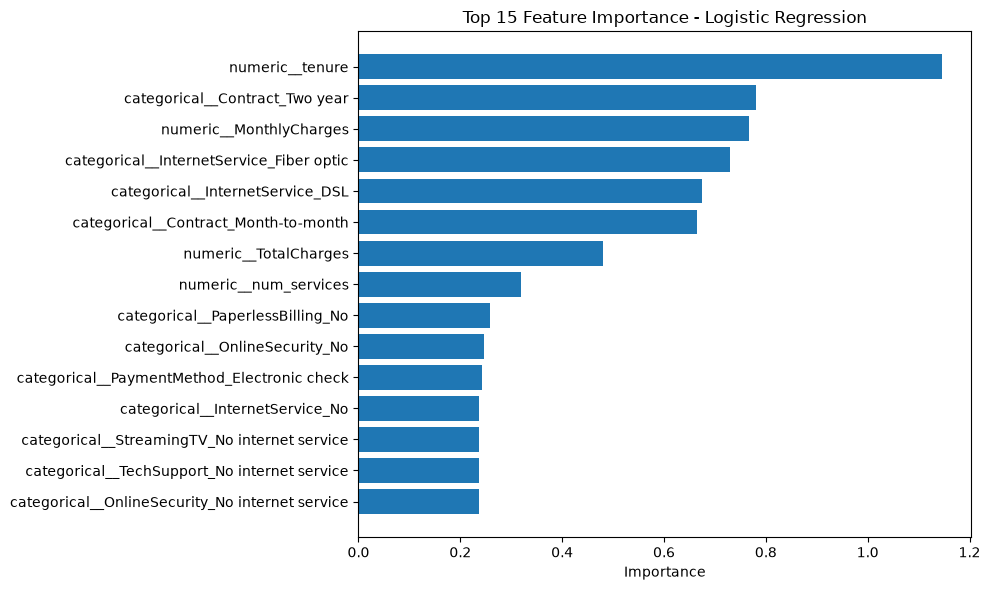


Top 15 Features: Random Forest
                                    Feature  Importance
                      numeric__TotalCharges    0.124239
                            numeric__tenure    0.109075
                 numeric__avg_monthly_spend    0.099832
                    numeric__MonthlyCharges    0.097797
       categorical__Contract_Month-to-month    0.074423
             categorical__Contract_Two year    0.033930
             categorical__OnlineSecurity_No    0.033627
                categorical__TechSupport_No    0.028404
                      numeric__num_services    0.026340
   categorical__InternetService_Fiber optic    0.025925
categorical__PaymentMethod_Electronic check    0.024268
               categorical__OnlineBackup_No    0.015549
                   categorical__gender_Male    0.014357
                 categorical__gender_Female    0.014112
             categorical__Contract_One year    0.013984


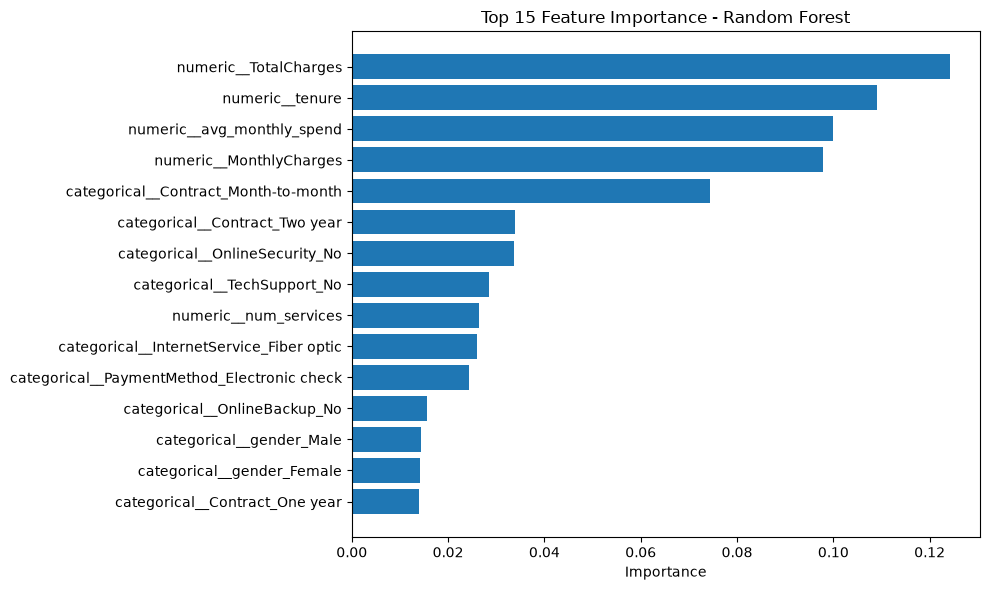

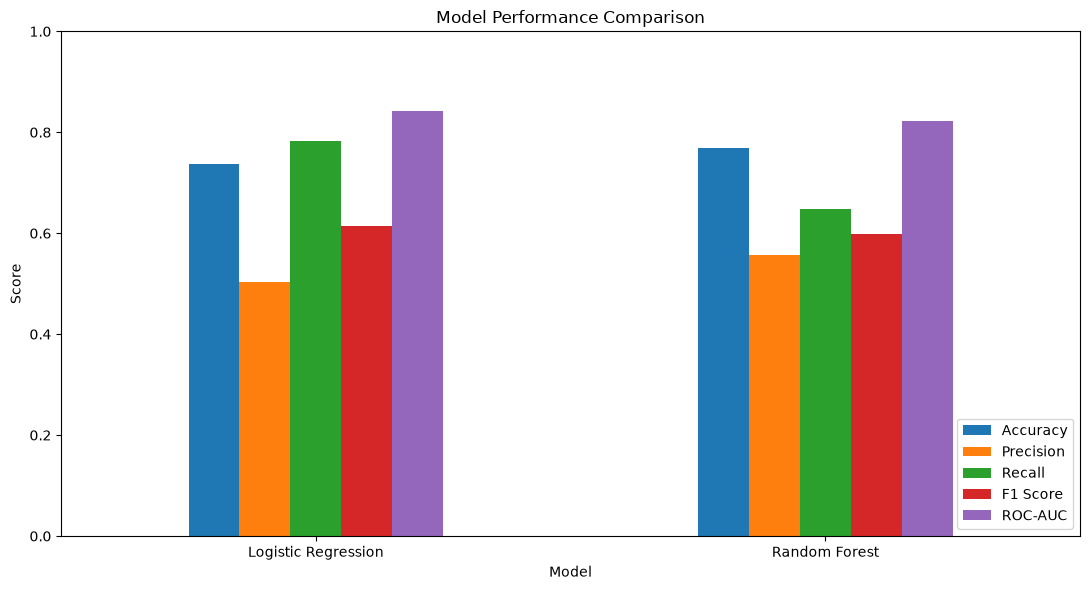

In [9]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# ============================================================
#  LOAD DATASET
# ============================================================

df = pd.read_csv(r"../day 17/cleaned_data.csv")

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

if "Churn" not in df.columns:
    raise ValueError("The dataset must contain a 'Churn' column.")

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove rows with a missing target
df = df.dropna(subset=["Churn"]).copy()

# Convert TotalCharges to numeric
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

# ============================================================
#  FEATURE ENGINEERING
# ============================================================

services = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Count subscribed services
if "num_services" not in df.columns:

    available_services = [
        c for c in services if c in df.columns
    ]

    df["num_services"] = (
        df[available_services].eq("Yes").sum(axis=1)
    )

    if "InternetService" in df.columns:
        df["num_services"] += (
            df["InternetService"]
            .ne("No")
            .astype(int)
        )

# Average total charges per month of tenure
if (
    "avg_monthly_spend" not in df.columns
    and {
        "TotalCharges",
        "tenure",
        "MonthlyCharges"
    }.issubset(df.columns)
):

    df["avg_monthly_spend"] = np.where(
        df["tenure"] > 0,
        df["TotalCharges"] / df["tenure"].replace(0, np.nan),
        df["MonthlyCharges"]
    )

print("\nFeatures available:", df.shape[1] - 1)

# ============================================================
# DEFINE FEATURES AND TARGET
# ============================================================

X = df.drop(
    columns=["Churn", "customerID"],
    errors="ignore"
)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

if y.isna().any():
    raise ValueError(
        "Unexpected values in Churn. Check df['Churn'].value_counts()."
    )

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True).round(3))

# ============================================================
#  TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean(), 3))
print("Testing churn rate:", round(y_test.mean(), 3))

# ============================================================
#  PREPROCESSING
# ============================================================

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# ============================================================
#  BUILD MODELS
# ============================================================

log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# ============================================================
# TRAIN MODELS
# ============================================================

print("\n" + "=" * 60)
print("TRAINING MODELS")
print("=" * 60)

log_model.fit(X_train, y_train)
print("Logistic Regression trained successfully.")

rf_model.fit(X_train, y_train)
print("Random Forest trained successfully.")

models = {
    "Logistic Regression": log_model,
    "Random Forest": rf_model
}

# ============================================================
#  EVALUATE MODELS
# ============================================================

results = {}
comparison = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results[name] = {
        "predictions": y_pred,
        "probabilities": y_prob
    }

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print("\nClassification report:")

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

comparison_df = pd.DataFrame(comparison).set_index("Model")

print("\nMODEL COMPARISON")
print(comparison_df.round(3))


# ============================================================
#  FEATURE IMPORTANCE
# ============================================================

# Get feature names after preprocessing
feature_names = (
    log_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Logistic Regression coefficients
log_coefficients = (
    log_model.named_steps["classifier"].coef_[0]
)

log_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": np.abs(log_coefficients),
    "Model": "Logistic Regression"
})

# Random Forest feature importance
rf_importances = (
    rf_model.named_steps["classifier"].feature_importances_
)

rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances,
    "Model": "Random Forest"
})

# Combine feature importance results
importance_df = pd.concat(
    [log_importance_df, rf_importance_df],
    ignore_index=True
)

# Display and plot the top 15 features
for model_name in importance_df["Model"].unique():

    top_features = (
        importance_df[
            importance_df["Model"] == model_name
        ]
        .sort_values("Importance", ascending=False)
        .head(15)
    )

    print(f"\nTop 15 Features: {model_name}")

    print(
        top_features[
            ["Feature", "Importance"]
        ].to_string(index=False)
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        top_features["Feature"][::-1],
        top_features["Importance"][::-1]
    )

    plt.title(f"Top 15 Feature Importance - {model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()



# ============================================================
#  MODEL COMPARISON CHART
# ============================================================

comparison_df[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ============================================================
#  SAVE RESULTS
# ============================================================

comparison_df.to_csv(
    "day18_model_comparison.csv"
)

importance_df.to_csv(
    "day18_feature_importance.csv",
    index=False
)

